# 04 · Identical power, different structure

On the cyclic group of length 12, consider occupied sites A = {0,1,4,6} and B = {0,1,3,7}. These configurations have equal occupancy, equal autocorrelation and equal power. No cyclic shift or reflection transforms one into the other. Such equality of pair correlations is called homometry.

## Setup
All examples use synthetic configurations. See THEORY.md for definitions, assumptions and proofs.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'observables').is_dir())
sys.path.insert(0,str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from observables.core import *
from observables.patterns import *
from observables.images import *
OUT=ROOT/'results'
OUT.mkdir(exist_ok=True)
plt.rcParams.update({'figure.figsize':(7.5,3.5),'figure.dpi':110,
                    'figure.constrained_layout.use':True,'axes.spines.top':False,'axes.spines.right':False})
def show(name):
    plt.savefig(OUT/(name+'.png'),dpi=150)
    plt.show()
def unit_circle(angles):
    return np.column_stack([np.cos(angles),np.sin(angles)])
SEED=41

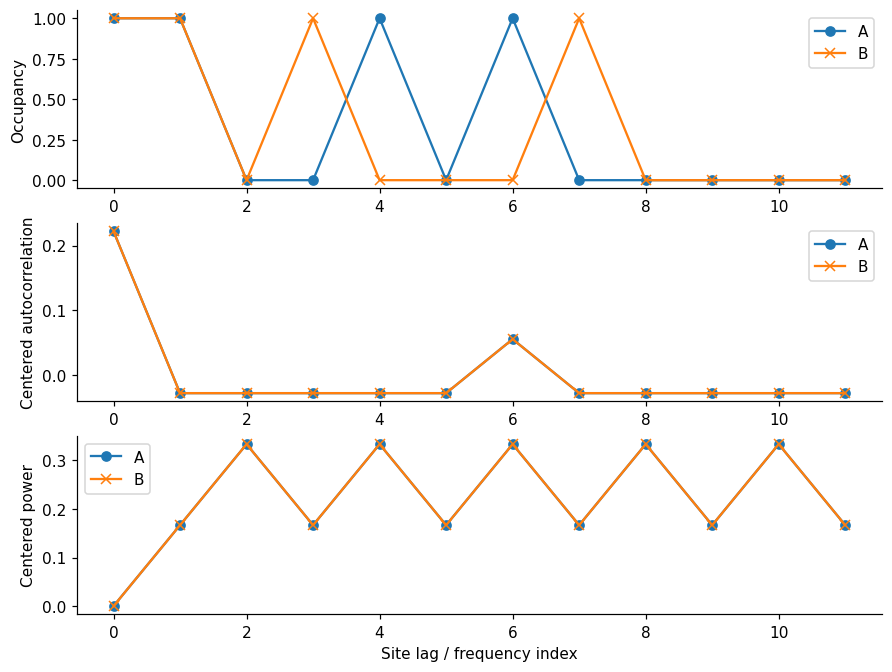

Maximum power discrepancy: 8.326672684688674e-17
Maximum autocorrelation discrepancy: 6.938893903907228e-17


In [3]:
a,b=homometric()
fig,axes=plt.subplots(3,1,figsize=(8,6))
for x,label,marker in [(a,'A','o'),(b,'B','x')]:
    axes[0].plot(range(12),x,marker=marker,label=label)
    axes[1].plot(range(12),autocorrelation(x),marker=marker,label=label)
    axes[2].plot(range(12),power(x),marker=marker,label=label)
for ax,label in zip(axes,['Occupancy','Centered autocorrelation','Centered power']):
    ax.set_ylabel(label);ax.legend()
axes[-1].set_xlabel('Site lag / frequency index');show('04_homometric')
assert not any(np.array_equal(a,np.roll(c,k)) for c in (b,b[::-1]) for k in range(12))
print('Maximum power discrepancy:',np.max(np.abs(power(a)-power(b))))
print('Maximum autocorrelation discrepancy:',np.max(np.abs(autocorrelation(a)-autocorrelation(b))))

## Third-order evidence
The cyclic bispectrum is $B(k,l)=F(k)F(l)F^*((k+l)\bmod N)/N$. Translation phases cancel, so it is translation invariant. Its phase carries information erased by the power spectrum. The third-order occupancy correlation is $T(r,s)=N^{-1}\sum_i x_i x_{i+r}x_{i+s}$.

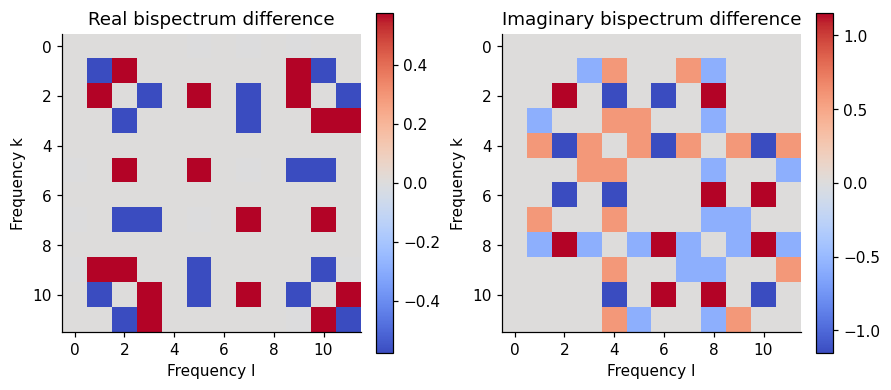

,r,s,T_A,T_B
0,1,3,0.000000,0.083333
1,1,4,0.083333,0.000000
2,1,6,0.083333,0.000000
3,1,7,0.000000,0.083333
4,2,6,0.000000,0.083333
5,2,8,0.083333,0.000000
6,2,9,0.083333,0.000000
7,2,11,0.000000,0.083333


In [5]:
ba,bb=bispectrum(a),bispectrum(b)
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
im=axes[0].imshow(ba.real-bb.real,cmap='coolwarm');axes[0].set_title('Real bispectrum difference')
fig.colorbar(im,ax=axes[0])
im=axes[1].imshow(ba.imag-bb.imag,cmap='coolwarm');axes[1].set_title('Imaginary bispectrum difference')
fig.colorbar(im,ax=axes[1])
for ax in axes:ax.set(xlabel='Frequency l',ylabel='Frequency k')
show('04_bispectrum')
third=lambda x,r,s:np.mean(x*np.roll(x,-r)*np.roll(x,-s))
differences=[(r,s,third(a,r,s),third(b,r,s)) for r in range(12) for s in range(12)
             if abs(third(a,r,s)-third(b,r,s))>1e-12]
display(pd.DataFrame(differences,columns=['r','s','T_A','T_B']).head(8))
assert np.linalg.norm(ba-bb)>1
assert np.allclose(ba,bispectrum(np.roll(a,5)),atol=1e-12)

## Interpretation
Autocorrelation and power are Fourier-equivalent descriptions of the same second-order information. Agreement in both provides one independent piece of evidence. The bispectrum distinguishes this constructed pair. No universal completeness claim is made for arbitrary sparse spectra, noise levels or groups. Choosing an even-order contrast-invariant observable also changes the behavior under intensity inversion.